<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/makemore_exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')
with open('/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt','r') as f:
  text = f.read().splitlines()

Mounted at /content/drive


In [4]:
words = text
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [5]:
chars = sorted(list(set(''.join(words))))
stoi = {c:i+1 for i,c in enumerate(chars)}
stoi['.']=0
itos = {i:s for s,i in stoi.items()}

vocab_szie = len(itos)
vocab_szie

27

In [8]:
import torch
block_size = 3

def build_data(words):
  X, Y = [], []
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # Fix: wrap ix in a list to allow list concatenation
  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X, Y # Fix: return the processed PyTorch tensors

In [9]:
import random
random.seed(42)
random.shuffle(words)
n1 = int(len(words) * 0.8)
n2 = int(len(words) * 0.9)

Xtr, Ytr = build_data(words[:n1])
Xval,Yval = build_data(words[n1:n2])
Xte,Yte = build_data(words[n2:])

In [12]:
# MLP
n_emb = 5
n_hidden = 100

g = torch.Generator().manual_seed(151413412)
C = torch.randn((vocab_szie, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * (5/3) / ((block_size * n_emb)**0.5)
#b1 = torch.randn(n_hidden, generator=0.01)
W2 = torch.randn((n_hidden, vocab_szie), generator=g) * 0.01
b2 = torch.randn(vocab_szie, generator=g)

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]

In [13]:
for p in parameters:
  p.requires_grad = True

print(sum(p.nelement() for p in parameters))

4562


In [15]:
max_steps = 200000
batch_size = 50

lossi = []
import torch.nn.functional as F

for i in range(max_steps):
  # minibatch
  ix = torch.randint(0,  Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  #foward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0],-1)
  hpreact = embcat @ W1
  bnmeani = hpreact.mean(0, keepdim=True)
  bnstdi = hpreact.std(0, keepdim=True)

  hpreact = bngain * (hpreact - bnmeani)/(bnstdi+0.000001) + bnbias

  with torch.no_grad():
    bnmean_running = 0.99* bnmean_running + 0.01 * bnmeani
    bnstd_running = 0.99 * bnstd_running + 0.01 * bnstdi

  h = torch.tanh(hpreact)

  logits = h @ W2 +b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update

  lr = 0.1 if i < 1e5 else 0.01

  for p in parameters:
    p.data += -lr * p.grad

  # track
  if i%10000==0:
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())



      0/ 200000: 4.0235
  10000/ 200000: 2.3420
  20000/ 200000: 2.2898
  30000/ 200000: 2.2317
  40000/ 200000: 2.5659
  50000/ 200000: 1.8636
  60000/ 200000: 2.5916
  70000/ 200000: 2.0687
  80000/ 200000: 2.1873
  90000/ 200000: 2.0880
 100000/ 200000: 2.1269
 110000/ 200000: 1.9921
 120000/ 200000: 2.3000
 130000/ 200000: 2.1606
 140000/ 200000: 2.3916
 150000/ 200000: 2.5087
 160000/ 200000: 2.0275
 170000/ 200000: 1.8999
 180000/ 200000: 2.3867
 190000/ 200000: 2.2848


In [16]:
from matplotlib import pyplot as plt
%matplotlib inline

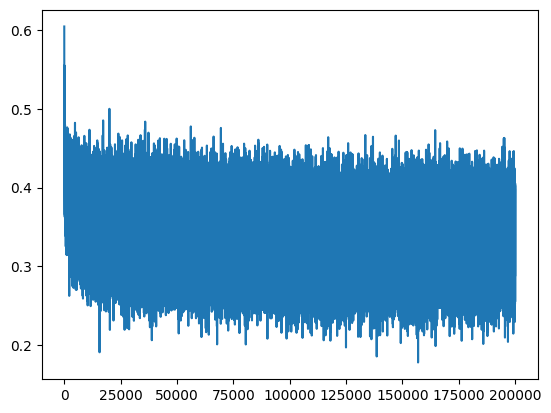

In [17]:
plt.plot(lossi)

In [20]:
@torch.no_grad
def split_loss(split):
  x,y = {
      'train': (Xtr,Ytr),
      'val': (Xval,Yval),
      'test': (Xte,Yte),

  }[split]
  emb = C[x]
  embcat = emb.view(emb.shape[0],-1)
  hpreact = embcat @ W1
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias

  h = torch.tanh(hpreact)

  logits = h @ W2 +b2
  loss = F.cross_entropy(logits,y)
  print(split, loss.item())

split_loss('train')
split_loss('val')


train 2.1513590812683105
val 2.173834800720215


In [22]:
# prediction

g = torch.Generator().manual_seed(19824761)
for _ in range(20):
  out = []
  context = [0] * block_size

  while True:
    # foward
    # Fix: Wrap context in a list [context] to represent a batch of size 1
    emb = C[torch.tensor([context])]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1

    hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias

    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)

    # sampling

    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break
  print(''.join(itos[i] for i in out))

kia.
zavatte.
ela.
riah.
kayleh.
rhe.
sudrianna.
byaireil.
toreeleigh.
bree.
ebelf.
ante.
zmerleone.
khannah.
johana.
tastino.
mary.
brory.
hastly.
annan.
